# Replicating *Universal Adversarial Perturbations* (Moosavi-Dezfooli et al., CVPR 2017)

PyTorch re-implementation of **Algorithm 1** (universal perturbation built by aggregating DeepFool steps and projecting onto the ℓp ball), ported from the official TensorFlow-1 code in `LTS4/universal` (`universal_pert.py`, `deepfool.py`).

**Data:** ImageNetV2 *matched-frequency* (10,000 natural images, same 1,000 ImageNet classes, MIT licence, no registration). It is downloaded automatically in Section 2. The fooling ratio only compares the model's prediction before and after adding `v`, so ground-truth labels are not needed. They are used only as a sanity check that the pretrained model loaded correctly.

**What this notebook reproduces**

| Exp. | Paper reference | What it shows |
|---|---|---|
| E1 | Table 1 | Fooling ratio on X and on held-out images |
| E2 | Fig. 8 | Universal vs. random noise of the same norm |
| E3 | Fig. 6 | Fooling ratio vs. size of X |
| E4 | Table 2 | Transfer of the perturbation to other architectures |
| E5 | Figs. 1, 3, 4 | Visualisation of `v` and perturbed images |
| E6 | Fig. 7 | "Dominant labels" |

**Before running:** `Runtime → Change runtime type → T4 GPU`. Then `Runtime → Run all`.

**Deviations from the paper (report these):** torchvision weights instead of Caffe models; ImageNetV2 instead of ILSVRC-2012; |X| = 4,000 instead of 10,000 by default (the paper's Fig. 6 shows ≈ 69 % for GoogLeNet at 4,000, versus 78.9 % at 10,000); DeepFool restricted to the top-10 classes, as in the official code.

## Summary (one-page view for the review)

**What this notebook does.** Replicates Moosavi-Dezfooli et al., *Universal Adversarial Perturbations* (CVPR 2017) in PyTorch: one fixed noise pattern **v**, built with Algorithm 1 (DeepFool + projection), added to any image to change the network's prediction. New in this version: **E7**, which tests the same attack on a Vision Transformer (ViT-B/16).

**Main results (GoogLeNet, ℓ∞, ξ = 10/255, |X| = 4,000, ImageNetV2).**

| | This run | Paper |
|---|---|---|
| Fooling rate on X | 59.0 % | — |
| Fooling rate on held-out images | 54.6 % | 78.9 % (\|X\| = 10,000) |
| Paper's Fig. 6 at \|X\| = 4,000 | — | ≈ 69 % |
| Universal v vs. random noise (same ℓ2 norm, Fig. 8) | 2–3× more images fooled | same claim |
| Transfer GoogLeNet → VGG-16 / ResNet-152 | 51.6 % / 34.9 % | 39.2 % / 45.5 % |

Why the gap with the paper: fewer images in X (4,000 vs 10,000; the paper's own Fig. 6 accounts for about 10 points), and the ℓ∞ clipping plateau (the fooling rate stops improving after pass 4, at 59 %).

**E7: Vision Transformer (fill in after running).**

| | GoogLeNet | ViT-B/16 |
|---|---|---|
| GoogLeNet v (from E1) | 54.6 % | __ % (transfer) |
| Random ±ξ noise | __ % | __ % |
| Own v, small run (\|X\| = 1,000, 2 passes) | __ % | __ % |

**Where the idea went next (papers citing the original, 2024–2026).** PSP-UAP (CVPR 2025, data-free UAPs for CNNs); C-PGC (ICCV 2025, universal perturbations for vision-language models); IRIS (NAACL 2025, universal jailbreak suffixes for LLMs); Schwarzer et al. (ICLR 2026, adversarial noise against speech-denoising models).

## 1. Configuration

In [1]:
# ===================== CONFIG =====================
MODEL_NAME      = "googlenet"               # googlenet | vgg16 | vgg19 | resnet50 | resnet152
TRANSFER_MODELS = ["vgg16", "resnet152"]    # E4: architectures to test the perturbation on

N_X   = 4000        # images used to compute v  (paper: 10,000)
N_VAL = 6000        # held-out images used to measure fooling rate (N_X + N_VAL <= 10,000)

NORM  = "inf"       # "inf" (paper xi = 10) or "2" (paper xi = 2000), both on the 0-255 scale
XI    = 10/255 if NORM == "inf" else 2000/255   # images here live in [0,1], so divide by 255
P     = float("inf") if NORM == "inf" else 2

DELTA           = 0.2    # stop when fooling rate on X >= 1 - DELTA (official default: 80 %)
MAX_PASSES      = 6      # passes over X
TIME_BUDGET_MIN = 100    # safety cut-off for the main run (Colab sessions time out)

DF_NUM_CLASSES = 10      # DeepFool only considers the top-10 classes (as in the official code)
DF_OVERSHOOT   = 0.02
DF_MAX_ITER    = 10

RUN_SIZE_SWEEP   = True             # E3 (costs extra time)
SWEEP_SIZES      = [500, 1000, 2000]
SWEEP_PASSES     = 3
COMPUTE_TRANSFER_V = False          # E4: also compute each transfer model's own v (slow; VGG is ~5x GoogLeNet)

USE_DRIVE = True        # save v, checkpoints and results to Google Drive
SEED = 0
# ==================================================

## 2. Setup, Drive and data download

In [3]:
import os, time, json, glob, random, math
from pathlib import Path
from collections import Counter

import numpy as np
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import models, transforms
from tqdm.auto import tqdm

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
if DEVICE == "cpu":
    print("WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU, otherwise this will take many hours.")

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/uap_replication")
else:
    OUT_DIR = Path("/content/uap_outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Outputs ->", OUT_DIR)

Device: cuda Tesla T4
Mounted at /content/drive
Outputs -> /content/drive/MyDrive/uap_replication


In [5]:
# ImageNetV2 matched-frequency (1.26 GB). Source: https://huggingface.co/datasets/vaishaal/ImageNetV2
import tarfile, zipfile, subprocess

DATA_DIR = Path("/content/data"); DATA_DIR.mkdir(exist_ok=True)
TAR_NAME = "imagenetv2-matched-frequency.tar.gz"
URL = f"https://huggingface.co/datasets/vaishaal/ImageNetV2/resolve/main/{TAR_NAME}"
DRIVE_TAR = OUT_DIR / TAR_NAME    # optional: put the archive here manually to skip the download

def extracted_dirs():
    return [d for d in DATA_DIR.glob("imagenetv2-*") if d.is_dir()]

if not extracted_dirs():
    tar_path = DRIVE_TAR if DRIVE_TAR.exists() else DATA_DIR / TAR_NAME
    if not tar_path.exists() or tar_path.stat().st_size < 1e9:      # missing or incomplete -> (re)download
        !wget -q --show-progress -O {tar_path} {URL}
    print("Archive type:", subprocess.run(["file", "-b", str(tar_path)], capture_output=True, text=True).stdout.strip())
    if tarfile.is_tarfile(tar_path):
        with tarfile.open(tar_path, "r:*") as t:     # auto-detects plain tar / gzip / bz2 / xz
            t.extractall(DATA_DIR)
    elif zipfile.is_zipfile(tar_path):
        with zipfile.ZipFile(tar_path) as z:
            z.extractall(DATA_DIR)
    else:
        raise RuntimeError("Downloaded file is not a tar or zip archive. Send me the 'Archive type' line above.")
    if tar_path.parent == DATA_DIR:
        tar_path.unlink()                            # free ~1.2 GB of Colab disk once extracted

print("Extracted folders:", [d.name for d in extracted_dirs()])
FILES = sorted(glob.glob(str(DATA_DIR / "imagenetv2-*" / "*" / "*.jpeg")))
print(len(FILES), "images found")   # expected: 10000
assert len(FILES) >= N_X + N_VAL, "Not enough images: reduce N_X / N_VAL or check the extraction."

Archive type: POSIX tar archive


/tmp/ipykernel_6016/971978317.py:19: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  t.extractall(DATA_DIR)


Extracted folders: ['imagenetv2-matched-frequency-format-val']
10000 images found


## 3. Load images (224×224, uint8 in RAM) and split into X / held-out

In [6]:
# Folder names are the ImageNet class index (0..999). Labels are only used for the clean-accuracy sanity check.
PREPROC = transforms.Compose([transforms.Resize(256), transforms.CenterCrop(224), transforms.PILToTensor()])

class ImgList(torch.utils.data.Dataset):
    def __init__(self, files): self.files = files
    def __len__(self): return len(self.files)
    def __getitem__(self, i):
        f = self.files[i]
        return PREPROC(Image.open(f).convert("RGB")), int(Path(f).parent.name)

def load_uint8(files, bs=256):
    dl = torch.utils.data.DataLoader(ImgList(files), batch_size=bs, num_workers=2)
    xs, ys = [], []
    for x, y in tqdm(dl, desc="decoding"):
        xs.append(x); ys.append(y)
    return torch.cat(xs), torch.cat(ys)

perm = np.random.RandomState(SEED).permutation(len(FILES))
files_X   = [FILES[i] for i in perm[:N_X]]
files_val = [FILES[i] for i in perm[N_X:N_X + N_VAL]]

X_u8,   y_X   = load_uint8(files_X)
VAL_u8, y_val = load_uint8(files_val)
if DEVICE == "cuda":
    X_u8, VAL_u8 = X_u8.pin_memory(), VAL_u8.pin_memory()
print("X:", tuple(X_u8.shape), " held-out:", tuple(VAL_u8.shape))

decoding:   0%|          | 0/16 [00:00<?, ?it/s]

decoding:   0%|          | 0/24 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7be8782960c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7be8782960c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

X: (4000, 3, 224, 224)  held-out: (6000, 3, 224, 224)


## 4. Models

In [7]:
WEIGHTS = {
    "googlenet": models.GoogLeNet_Weights.IMAGENET1K_V1,
    "vgg16":     models.VGG16_Weights.IMAGENET1K_V1,
    "vgg19":     models.VGG19_Weights.IMAGENET1K_V1,
    "resnet50":  models.ResNet50_Weights.IMAGENET1K_V1,
    "resnet152": models.ResNet152_Weights.IMAGENET1K_V1,
}
CATEGORIES = WEIGHTS["googlenet"].meta["categories"]

class Normalize(nn.Module):
    # Normalisation lives INSIDE the model, so perturbations are defined in pixel space [0,1]
    def __init__(self):
        super().__init__()
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x): return (x - self.mean) / self.std

def load_model(name):
    net = getattr(models, name)(weights=WEIGHTS[name])
    m = nn.Sequential(Normalize(), net).eval().to(DEVICE)
    for p in m.parameters(): p.requires_grad_(False)
    return m

model = load_model(MODEL_NAME)
print("Loaded", MODEL_NAME)

Downloading: "https://download.pytorch.org/models/googlenet-1378be20.pth" to /root/.cache/torch/hub/checkpoints/googlenet-1378be20.pth


100%|██████████| 49.7M/49.7M [00:00<00:00, 167MB/s]


Loaded googlenet


## 5. Core algorithm (port of `deepfool.py` and `universal_pert.py`)

* `deepfool`: minimal perturbation sending `x` across the nearest decision boundary among the top-10 classes (Eq. 1 of the paper). The 10 class gradients are obtained with a single backward pass on a batch of 10 copies of the image.
* `proj_lp`: projection on the ℓ2 / ℓ∞ ball of radius ξ (operator 𝒫p,ξ).
* `universal_perturbation`: Algorithm 1. Each pass shuffles X; for every image still correctly classified, `v ← 𝒫(v + Δv_i)`; stop when the fooling rate on X ≥ 1 − δ.

In [8]:
def deepfool(model, x, num_classes=10, overshoot=0.02, max_iter=10):
    # x: (1,3,H,W) in pixel space. Returns (r_tot, n_iter, new_label).
    with torch.no_grad():
        f0 = model(x)[0]
    I = f0.argsort(descending=True)[:num_classes]
    label = I[0].item()
    r_tot = torch.zeros_like(x)
    x_pert = x.clone()
    rows = torch.arange(num_classes, device=x.device)
    k_i, loop_i = label, 0
    while k_i == label and loop_i < max_iter:
        xr = x_pert.repeat(num_classes, 1, 1, 1).requires_grad_(True)
        logits = model(xr)
        grads = torch.autograd.grad(logits[rows, I].sum(), xr)[0]     # row j = d f_{I[j]} / dx
        f = logits[0, I].detach()
        w = grads[1:] - grads[:1]                                       # w_k = grad_k - grad_label
        fk = (f[1:] - f[0]).abs()
        wn = w.flatten(1).norm(dim=1) + 1e-8
        pert = fk / wn
        l = pert.argmin()
        r_tot = r_tot + (pert[l] + 1e-4) * w[l:l+1] / wn[l]
        x_pert = (x + (1 + overshoot) * r_tot).detach()
        loop_i += 1
        with torch.no_grad():
            k_i = model(x_pert).argmax(1).item()
    return (1 + overshoot) * r_tot, loop_i, k_i


def proj_lp(v, xi, p):
    if p == 2:
        return v * min(1.0, xi / (v.norm().item() + 1e-12))
    if p == float("inf"):
        return v.clamp(-xi, xi)
    raise ValueError("Only p = 2 and p = inf are supported (as in the official code).")


@torch.no_grad()
def predict(model, X_u8, v=None, bs=250):
    out = []
    for i in range(0, len(X_u8), bs):
        x = X_u8[i:i+bs].to(DEVICE, non_blocking=True).float().div_(255)
        if v is not None:
            x = (x + v).clamp_(0, 1)          # perturbed image must remain a valid image
        out.append(model(x).argmax(1).cpu())
    return torch.cat(out)

def fooling_rate(model, X_u8, v, clean_pred):
    return (predict(model, X_u8, v) != clean_pred).float().mean().item()


def universal_perturbation(model, X_u8, clean_pred, xi, p, delta=0.2, max_passes=6,
                           time_budget_min=None, ckpt_path=None, tag=""):
    v = torch.zeros(1, 3, 224, 224, device=DEVICE)
    history, t0, n = [], time.time(), len(X_u8)
    out_of_time = lambda: time_budget_min and (time.time() - t0) / 60 > time_budget_min
    for pass_i in range(max_passes):
        n_upd = 0
        for idx in tqdm(torch.randperm(n).tolist(), desc=f"{tag} pass {pass_i+1}", leave=False):
            x = X_u8[idx:idx+1].to(DEVICE).float().div_(255)
            with torch.no_grad():
                not_fooled = model(x + v).argmax(1).item() == clean_pred[idx].item()
            if not_fooled:
                dr, it, _ = deepfool(model, x + v, DF_NUM_CLASSES, DF_OVERSHOOT, DF_MAX_ITER)
                if it < DF_MAX_ITER - 1:                     # only use converged DeepFool steps (official code)
                    v = proj_lp(v + dr, xi, p); n_upd += 1
            if out_of_time(): break
        fr = fooling_rate(model, X_u8, v, clean_pred)
        mins = (time.time() - t0) / 60
        history.append({"pass": pass_i + 1, "fooling_rate_X": fr, "updates": n_upd, "minutes": mins})
        print(f"{tag} pass {pass_i+1}: fooling rate on X = {fr:.1%}  ({n_upd} updates, {mins:.1f} min)")
        if ckpt_path: torch.save(v.cpu(), ckpt_path)
        if fr >= 1 - delta:
            print("Target fooling rate reached."); break
        if out_of_time():
            print("Time budget reached."); break
    return v, history

## 6. Sanity check: clean predictions and accuracy

In [9]:
clean_X   = predict(model, X_u8)
clean_val = predict(model, VAL_u8)
print(f"{MODEL_NAME} clean top-1 on held-out ImageNetV2: {(clean_val == y_val).float().mean():.1%}")
# torchvision reference on ImageNet val: GoogLeNet ~69.8 %, VGG-16 ~71.6 %, ResNet-152 ~78.3 %.
# ImageNetV2 is known to be ~10-12 points harder, so ~58-67 % here means the model is loaded correctly.

googlenet clean top-1 on held-out ImageNetV2: 58.5%


## E1. Compute the universal perturbation (Table 1)

In [10]:
ckpt = OUT_DIR / f"v_{MODEL_NAME}_l{NORM}_ckpt.pt"
v, hist = universal_perturbation(model, X_u8, clean_X, XI, P, DELTA, MAX_PASSES,
                                 TIME_BUDGET_MIN, ckpt, tag=MODEL_NAME)
np.save(OUT_DIR / f"universal_{MODEL_NAME}_l{NORM}.npy", v.cpu().numpy())

googlenet pass 1:   0%|          | 0/4000 [00:00<?, ?it/s]

googlenet pass 1: fooling rate on X = 44.4%  (2828 updates, 5.3 min)


googlenet pass 2:   0%|          | 0/4000 [00:00<?, ?it/s]

googlenet pass 2: fooling rate on X = 52.6%  (2000 updates, 8.9 min)


googlenet pass 3:   0%|          | 0/4000 [00:00<?, ?it/s]

googlenet pass 3: fooling rate on X = 55.8%  (1762 updates, 12.1 min)


... (2 outputs left out)

googlenet pass 5:   0%|          | 0/4000 [00:00<?, ?it/s]

googlenet pass 5: fooling rate on X = 58.8%  (1602 updates, 17.7 min)


googlenet pass 6:   0%|          | 0/4000 [00:00<?, ?it/s]

googlenet pass 6: fooling rate on X = 59.0%  (1554 updates, 20.2 min)


In [11]:
PAPER_T1 = {"inf": {"vgg16": 78.3, "vgg19": 77.8, "googlenet": 78.9, "resnet152": 84.0},
            "2":   {"vgg16": 90.3, "vgg19": 84.5, "googlenet": 82.0, "resnet152": 88.5}}
fr_X   = fooling_rate(model, X_u8, v, clean_X)
fr_val = fooling_rate(model, VAL_u8, v, clean_val)
print(f"Model: {MODEL_NAME} | norm l{NORM} | xi = {XI*255:.0f}/255 | |X| = {N_X}")
print(f"  ||v||_inf = {v.abs().max().item()*255:.1f}/255,  ||v||_2 = {v.norm().item()*255:.0f} (0-255 scale)")
print(f"  Fooling rate on X        : {fr_X:.1%}")
print(f"  Fooling rate on held-out : {fr_val:.1%}")
print(f"  Paper (Table 1, val, |X|=10k): {PAPER_T1[NORM].get(MODEL_NAME, 'n/a')} %")
RESULTS = {"model": MODEL_NAME, "norm": NORM, "xi_255": XI*255, "n_X": N_X, "n_val": N_VAL,
           "fooling_X": fr_X, "fooling_val": fr_val, "history": hist}

Model: googlenet | norm linf | xi = 10/255 | |X| = 4000
  ||v||_inf = 10.0/255,  ||v||_2 = 2660 (0-255 scale)
  Fooling rate on X        : 59.0%
  Fooling rate on held-out : 54.6%
  Paper (Table 1, val, |X|=10k): 78.9 %


## E2. Universal vs. random perturbations (Fig. 8)
Same-norm random noise should fool only a small fraction of images (paper: ≈ 10 % at ℓ2 = 2000), while `v` fools most of them. We also include a single-image DeepFool perturbation (computed for one image and applied to all), as in Fig. 8.

Universal v          : 54.8%
Random +/-xi (l_inf) : 24.8%
Random, same l2 norm : 19.0%


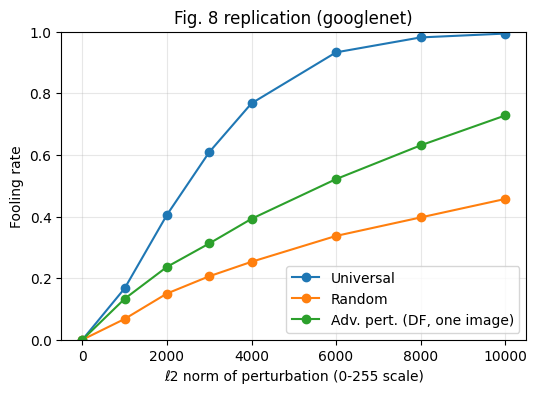

Note: v was computed for l_inf; the paper's Fig. 8 uses an l2-computed v (set NORM='2' to match exactly).


In [12]:
VAL_SUB = VAL_u8[:2000]; clean_sub = clean_val[:2000]
torch.manual_seed(SEED)

# Same-budget comparison at the paper's xi
v_rand_inf = XI * torch.sign(torch.randn_like(v))             # random vertex of the l_inf ball (strongest random noise at this budget)
g = torch.randn_like(v); v_rand_l2 = g / g.norm() * v.norm()  # random direction, same l2 norm as v
print(f"Universal v          : {fooling_rate(model, VAL_SUB, v, clean_sub):.1%}")
print(f"Random +/-xi (l_inf) : {fooling_rate(model, VAL_SUB, v_rand_inf, clean_sub):.1%}")
print(f"Random, same l2 norm : {fooling_rate(model, VAL_SUB, v_rand_l2, clean_sub):.1%}")

# Phase-transition curve: rescale each direction to a given l2 norm (0-255 scale, as in Fig. 8)
x0 = X_u8[:1].to(DEVICE).float() / 255
r_df, _, _ = deepfool(model, x0, DF_NUM_CLASSES, DF_OVERSHOOT, 50)
dirs = {"Universal": v, "Random": g, "Adv. pert. (DF, one image)": r_df}
norms_255 = [0, 1000, 2000, 3000, 4000, 6000, 8000, 10000]
curves = {}
for name, d in dirs.items():
    u = d / d.norm()
    curves[name] = [fooling_rate(model, VAL_SUB, u * (n / 255), clean_sub) if n else 0.0 for n in norms_255]
plt.figure(figsize=(6, 4))
for name, c in curves.items(): plt.plot(norms_255, c, marker="o", label=name)
plt.xlabel("ℓ2 norm of perturbation (0-255 scale)"); plt.ylabel("Fooling rate"); plt.ylim(0, 1)
plt.title(f"Fig. 8 replication ({MODEL_NAME})"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(OUT_DIR / "fig8_phase_transition.png", dpi=150, bbox_inches="tight"); plt.show()
RESULTS["fig8"] = {"norms_255": norms_255, "curves": curves}
if NORM == "inf":
    print("Note: v was computed for l_inf; the paper's Fig. 8 uses an l2-computed v (set NORM='2' to match exactly).")

## E3. Fooling rate vs. size of X (Fig. 6)

|X|=500 pass 1:   0%|          | 0/500 [00:00<?, ?it/s]

|X|=500 pass 1: fooling rate on X = 17.6%  (447 updates, 0.9 min)


|X|=500 pass 2:   0%|          | 0/500 [00:00<?, ?it/s]

|X|=500 pass 2: fooling rate on X = 22.6%  (404 updates, 1.5 min)


|X|=500 pass 3:   0%|          | 0/500 [00:00<?, ?it/s]

|X|=500 pass 3: fooling rate on X = 29.6%  (379 updates, 2.0 min)


... (8 outputs left out)

|X|=2000 pass 2:   0%|          | 0/2000 [00:00<?, ?it/s]

|X|=2000 pass 2: fooling rate on X = 37.7%  (1341 updates, 5.4 min)


|X|=2000 pass 3:   0%|          | 0/2000 [00:00<?, ?it/s]

|X|=2000 pass 3: fooling rate on X = 43.0%  (1188 updates, 7.4 min)


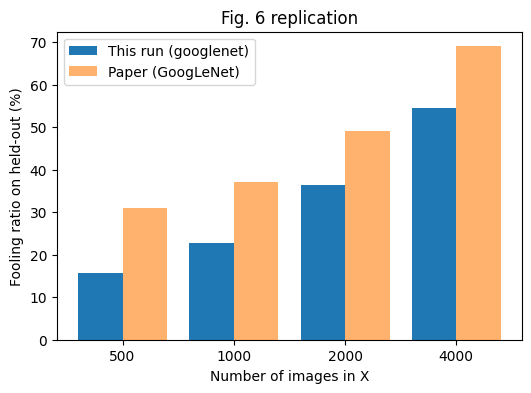

{500: '15.6%', 1000: '22.9%', 2000: '36.3%', 4000: '54.6%'}


In [13]:
if RUN_SIZE_SWEEP:
    PAPER_F6 = {500: 31, 1000: 37, 2000: 49, 4000: 69}   # read off Fig. 6 (GoogLeNet, l_inf, xi=10)
    sweep = {}
    for m in SWEEP_SIZES:
        v_m, _ = universal_perturbation(model, X_u8[:m], clean_X[:m], XI, P, DELTA, SWEEP_PASSES, tag=f"|X|={m}")
        sweep[m] = fooling_rate(model, VAL_u8, v_m, clean_val)
    sweep[N_X] = fr_val
    sizes = sorted(sweep)
    plt.figure(figsize=(6, 4)); xs = np.arange(len(sizes))
    plt.bar(xs - .2, [100*sweep[s] for s in sizes], .4, label=f"This run ({MODEL_NAME})")
    plt.bar(xs + .2, [PAPER_F6.get(s, np.nan) for s in sizes], .4, label="Paper (GoogLeNet)", alpha=.6)
    plt.xticks(xs, sizes); plt.xlabel("Number of images in X"); plt.ylabel("Fooling ratio on held-out (%)")
    plt.legend(); plt.title("Fig. 6 replication")
    plt.savefig(OUT_DIR / "fig6_size_of_X.png", dpi=150, bbox_inches="tight"); plt.show()
    print({k: f"{x:.1%}" for k, x in sweep.items()})
    RESULTS["fig6"] = sweep

## E4. Cross-model universality (Table 2)

In [14]:
PAPER_T2 = {  # row = model v was computed on, col = model evaluated (l_inf, xi = 10)
    "googlenet": {"googlenet": 78.9, "vgg16": 39.2, "vgg19": 39.8, "resnet152": 45.5},
    "vgg16":     {"googlenet": 56.5, "vgg16": 78.3, "vgg19": 73.1, "resnet152": 63.4},
    "vgg19":     {"googlenet": 53.6, "vgg16": 73.5, "vgg19": 77.8, "resnet152": 58.0},
    "resnet152": {"googlenet": 50.5, "vgg16": 47.0, "vgg19": 45.5, "resnet152": 84.0},
}
all_models = [MODEL_NAME] + [m for m in TRANSFER_MODELS if m != MODEL_NAME]
perts = {MODEL_NAME: v}
loaded = {MODEL_NAME: (model, clean_X, clean_val)}
for name in all_models[1:]:
    m = load_model(name)
    loaded[name] = (m, predict(m, X_u8) if COMPUTE_TRANSFER_V else None, predict(m, VAL_u8))
    if COMPUTE_TRANSFER_V:
        perts[name], _ = universal_perturbation(m, X_u8, loaded[name][1], XI, P, DELTA, MAX_PASSES,
                                                TIME_BUDGET_MIN, OUT_DIR / f"v_{name}_l{NORM}_ckpt.pt", tag=name)
        np.save(OUT_DIR / f"universal_{name}_l{NORM}.npy", perts[name].cpu().numpy())

table = {}
for src, vp in perts.items():
    table[src] = {}
    for dst in all_models:
        m, _, cv = loaded[dst]
        table[src][dst] = fooling_rate(m, VAL_u8, vp, cv)

header = "computed on \\ tested on".ljust(26) + "".join(d.ljust(22) for d in all_models)
print(header); print("-" * len(header))
for src in table:
    row = src.ljust(26)
    for dst in all_models:
        ref = PAPER_T2.get(src, {}).get(dst)
        row += (f"{table[src][dst]:.1%}" + (f" (paper {ref})" if ref and NORM == "inf" else "")).ljust(22)
    print(row)
RESULTS["table2"] = table
for name in all_models[1:]: del loaded[name]
torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:05<00:00, 102MB/s] 


Downloading: "https://download.pytorch.org/models/resnet152-394f9c45.pth" to /root/.cache/torch/hub/checkpoints/resnet152-394f9c45.pth


100%|██████████| 230M/230M [00:02<00:00, 101MB/s]


computed on \ tested on   googlenet             vgg16                 resnet152             
--------------------------------------------------------------------------------------------
googlenet                 54.6% (paper 78.9)    51.6% (paper 39.2)    34.9% (paper 45.5)    


## E5. Visualisations (Figs. 1, 3, 4)

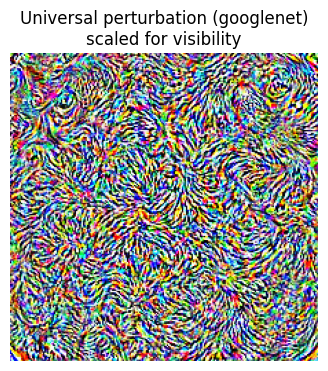

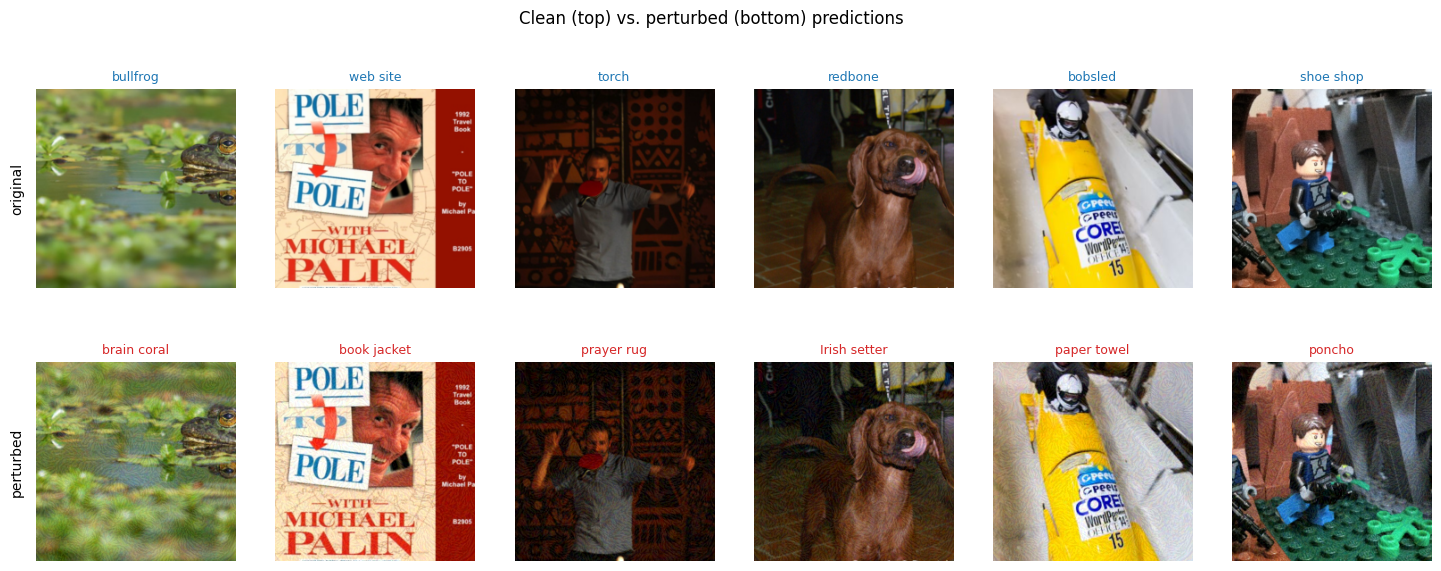

In [15]:
def show(t): return t[0].permute(1, 2, 0).cpu().numpy()

vv = v[0].permute(1, 2, 0).cpu().numpy()
plt.figure(figsize=(4, 4)); plt.imshow((vv - vv.min()) / (vv.max() - vv.min())); plt.axis("off")
plt.title(f"Universal perturbation ({MODEL_NAME})\nscaled for visibility")
plt.savefig(OUT_DIR / "fig4_perturbation.png", dpi=150, bbox_inches="tight"); plt.show()

idx = torch.where(predict(model, VAL_u8[:300], v) != clean_val[:300])[0][:6].tolist()
assert idx, "No fooled images in the first 300 - check E1 results."
fig, ax = plt.subplots(2, len(idx), figsize=(3 * len(idx), 6.5), squeeze=False)
for j, i in enumerate(idx):
    x = VAL_u8[i:i+1].float().div(255).to(DEVICE)
    xp = (x + v).clamp(0, 1)
    with torch.no_grad():
        a, b = model(x).argmax(1).item(), model(xp).argmax(1).item()
    ax[0, j].imshow(show(x));  ax[0, j].set_title(CATEGORIES[a], fontsize=9, color="tab:blue")
    ax[1, j].imshow(show(xp)); ax[1, j].set_title(CATEGORIES[b], fontsize=9, color="tab:red")
    ax[0, j].axis("off"); ax[1, j].axis("off")
ax[0, 0].text(-30, 112, "original", rotation=90, va="center"); ax[1, 0].text(-30, 112, "perturbed", rotation=90, va="center")
plt.suptitle("Clean (top) vs. perturbed (bottom) predictions")
plt.savefig(OUT_DIR / "fig3_examples.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
# Optional: test on your own photo (Fig. 3, last row in the paper). Upload any JPG/PNG when prompted.
TRY_OWN_IMAGE = False
if TRY_OWN_IMAGE:
    from google.colab import files
    up = files.upload()
    for fname in up:
        x = PREPROC(Image.open(fname).convert("RGB"))[None].float().div(255).to(DEVICE)
        xp = (x + v).clamp(0, 1)
        with torch.no_grad():
            a, b = model(x).argmax(1).item(), model(xp).argmax(1).item()
        fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
        ax[0].imshow(show(x)); ax[0].set_title(CATEGORIES[a]); ax[1].imshow(show(xp)); ax[1].set_title(CATEGORIES[b])
        for a_ in ax: a_.axis("off")
        plt.show()

## E6. Dominant labels (Fig. 7)

636 distinct target labels among 3276 fooled images


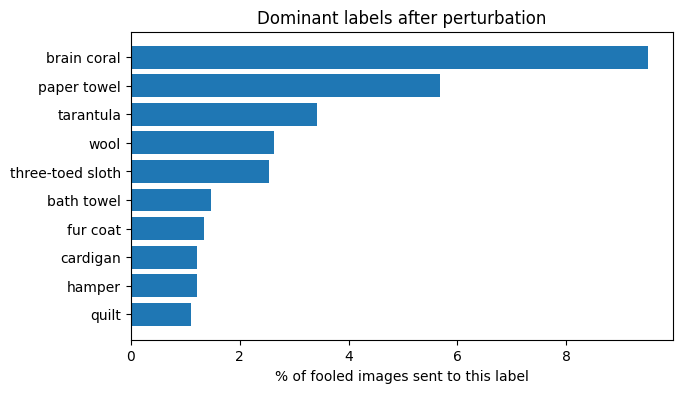

In [16]:
pert_val = predict(model, VAL_u8, v)
fooled = pert_val != clean_val
top = Counter(pert_val[fooled].tolist()).most_common(10)
print(f"{len(set(pert_val[fooled].tolist()))} distinct target labels among {fooled.sum().item()} fooled images")
plt.figure(figsize=(7, 4))
plt.barh([CATEGORIES[k] for k, _ in top][::-1], [100 * c / fooled.sum().item() for _, c in top][::-1])
plt.xlabel("% of fooled images sent to this label"); plt.title("Dominant labels after perturbation")
plt.savefig(OUT_DIR / "fig7_dominant_labels.png", dpi=150, bbox_inches="tight"); plt.show()
RESULTS["dominant_labels"] = [(CATEGORIES[k], c) for k, c in top]

## Save summary

In [17]:
with open(OUT_DIR / f"results_{MODEL_NAME}_l{NORM}.json", "w") as f:
    json.dump(RESULTS, f, indent=2, default=float)
print("Saved to", OUT_DIR)
print(json.dumps({k: RESULTS[k] for k in ["model", "norm", "n_X", "fooling_X", "fooling_val"]}, indent=2, default=float))

Saved to /content/drive/MyDrive/uap_replication
{
  "model": "googlenet",
  "norm": "inf",
  "n_X": 4000,
  "fooling_X": 0.590499997138977,
  "fooling_val": 0.5460000038146973
}


# E7 — Extension: does Algorithm 1 work on a Vision Transformer?

Benz et al. (2021) compared ViTs and CNNs under universal perturbations, but they used a different algorithm (Zhang et al., CVPR 2020), not the paper's Algorithm 1. So the question "how does the **original** algorithm do on a ViT?" is still open. This section answers it at small scale with torchvision's `vit_b_16` (same 224×224 input and the same ImageNet normalization as the CNNs).

**How to run in a fresh Colab session (GPU runtime):** run cells 2 → 13 as usual (config, setup, data, model, functions, clean predictions) with `MODEL_NAME = "googlenet"`. **Skip cell 15** (the 20-minute main run): E7.0 loads the saved perturbation from Drive instead. Then run the E7 cells in order. Expected time: about 5 minutes for E7.0–E7.2, then up to about 1 hour for E7.3 (the ViT run is capped by `SMALL_BUDGET`).

Three questions:
1. **Transfer (E7.2):** does the perturbation built on GoogLeNet fool the ViT?
2. **Direct attack (E7.3):** if we run Algorithm 1 on the ViT itself, at the same reduced settings as a GoogLeNet run, how far does it get?
3. **Cross-transfer (E7.4):** do the two small perturbations fool each other's model?

In [ ]:
# E7.0  Load the saved GoogLeNet perturbation (skip cell 15 in a fresh session)
assert MODEL_NAME == "googlenet", "E7 compares against the GoogLeNet run: set MODEL_NAME = 'googlenet' in cell 2."
V_PATH = OUT_DIR / "universal_googlenet_linf.npy"
if "v" not in globals():
    v = torch.from_numpy(np.load(V_PATH)).to(DEVICE)
    print("Loaded v from", V_PATH)
print(f"||v||_inf = {v.abs().max().item()*255:.1f}/255,  ||v||_2 = {v.norm().item()*255:.0f}   (expected: 10.0 and 2660)")
E7 = {}

In [ ]:
# E7.1  Load ViT-B/16 through the same wrapper (normalisation inside the model, pixels in [0,1])
WEIGHTS["vit_b_16"] = models.ViT_B_16_Weights.IMAGENET1K_V1
vit = load_model("vit_b_16")
clean_X_vit   = predict(vit, X_u8)
clean_val_vit = predict(vit, VAL_u8)
acc = (clean_val_vit == y_val).float().mean().item()
print(f"vit_b_16 clean top-1 on held-out ImageNetV2: {acc:.1%}")
# torchvision reference on ImageNet val: ViT-B/16 (IMAGENET1K_V1) ~81.1 %. ImageNetV2 is ~10-12 points harder,
# so roughly 68-72 % here means the model and preprocessing are correct.
E7["vit_clean_top1"] = acc

In [ ]:
# E7.2  Transfer: GoogLeNet's v on the ViT, against a random-noise baseline of the same l_inf budget
torch.manual_seed(SEED)
v_rand = XI * torch.sign(torch.randn_like(v))          # random vertex of the l_inf ball (strongest random noise at this budget)

E7["googlenet_v"] = {"googlenet": fooling_rate(model, VAL_u8, v, clean_val),
                     "vit_b_16":  fooling_rate(vit,   VAL_u8, v, clean_val_vit)}
E7["random"]      = {"googlenet": fooling_rate(model, VAL_u8, v_rand, clean_val),
                     "vit_b_16":  fooling_rate(vit,   VAL_u8, v_rand, clean_val_vit)}

print("Perturbation \\ tested on".ljust(28) + "googlenet".ljust(14) + "vit_b_16")
for name in ["googlenet_v", "random"]:
    print(name.ljust(28) + f"{E7[name]['googlenet']:.1%}".ljust(14) + f"{E7[name]['vit_b_16']:.1%}")

In [ ]:
# E7.3  Run Algorithm 1 directly on each model, with identical reduced settings so the comparison is fair
SMALL_N, SMALL_PASSES, SMALL_BUDGET = 1000, 2, 60      # images in X, passes, minutes per model (Colab safety cap)
X_small = X_u8[:SMALL_N]

small = {}
for name, m, cX, cV in [("googlenet", model, clean_X, clean_val),
                        ("vit_b_16",  vit,   clean_X_vit, clean_val_vit)]:
    t0 = time.time()
    v_s, h = universal_perturbation(m, X_small, cX[:SMALL_N], XI, P, DELTA, SMALL_PASSES, SMALL_BUDGET,
                                    OUT_DIR / f"v_{name}_small_ckpt.pt", tag=f"{name} small")
    np.save(OUT_DIR / f"universal_{name}_l{NORM}_small.npy", v_s.cpu().numpy())
    small[name] = {"v": v_s, "history": h,
                   "fooling_val": fooling_rate(m, VAL_u8, v_s, cV),
                   "linf_255": v_s.abs().max().item() * 255,
                   "l2_255": v_s.norm().item() * 255,
                   "minutes": (time.time() - t0) / 60}
    print(f"{name}: held-out fooling rate {small[name]['fooling_val']:.1%} | "
          f"||v||_2 = {small[name]['l2_255']:.0f} | {small[name]['minutes']:.1f} min\n")

In [ ]:
# E7.4  Cross-transfer between the two small perturbations, plus a summary chart
cross = {}
for src in small:
    cross[src] = {"googlenet": fooling_rate(model, VAL_u8, small[src]["v"], clean_val),
                  "vit_b_16":  fooling_rate(vit,   VAL_u8, small[src]["v"], clean_val_vit)}

print("v computed on \\ tested on".ljust(28) + "googlenet".ljust(14) + "vit_b_16")
for src in cross:
    print(src.ljust(28) + f"{cross[src]['googlenet']:.1%}".ljust(14) + f"{cross[src]['vit_b_16']:.1%}")

rows = {"Random ±ξ": E7["random"],
        "GoogLeNet v (E1, |X|=4000)": E7["googlenet_v"],
        f"GoogLeNet v (small, |X|={SMALL_N})": cross["googlenet"],
        f"ViT v (small, |X|={SMALL_N})": cross["vit_b_16"]}
xs = np.arange(len(rows))
plt.figure(figsize=(8, 4))
plt.bar(xs - .2, [100 * r["googlenet"] for r in rows.values()], .4, label="tested on GoogLeNet")
plt.bar(xs + .2, [100 * r["vit_b_16"]  for r in rows.values()], .4, label="tested on ViT-B/16")
plt.xticks(xs, list(rows), rotation=15, ha="right"); plt.ylabel("Fooling rate on held-out (%)")
plt.title(f"E7: universal perturbations on GoogLeNet vs ViT-B/16 (ℓ{NORM}, ξ = {XI*255:.0f}/255)")
plt.legend(); plt.grid(axis="y", alpha=.3)
plt.savefig(OUT_DIR / "e7_vit_comparison.png", dpi=150, bbox_inches="tight"); plt.show()

In [ ]:
# E7.5  Save everything needed to report E7 without re-running
E7["small_settings"] = {"n_X": SMALL_N, "passes": SMALL_PASSES, "budget_min": SMALL_BUDGET}
E7["small_run"] = {k: {kk: vv for kk, vv in d.items() if kk != "v"} for k, d in small.items()}
E7["cross_transfer"] = cross
with open(OUT_DIR / f"results_e7_vit_l{NORM}.json", "w") as f:
    json.dump(E7, f, indent=2, default=float)
print("Saved to", OUT_DIR / f"results_e7_vit_l{NORM}.json")
print(json.dumps({k: E7[k] for k in ["vit_clean_top1", "googlenet_v", "random", "cross_transfer"]}, indent=2, default=float))

### How to read E7

- **Sanity check first.** ViT clean accuracy around 68–72 % (E7.1) means the model loaded correctly. The GoogLeNet row in E7.2 should reproduce 54.6 %.
- **Transfer (E7.2).** Compare GoogLeNet's v on the ViT against random noise on the ViT. If the two are close, the CNN-built pattern carries no ViT-specific information, which matches Benz et al.'s finding that perturbations transfer poorly between CNNs and ViTs.
- **Direct attack (E7.3).** Both models get exactly the same budget (|X|, passes, ξ). A lower fooling rate for the ViT at equal settings means Algorithm 1 makes slower progress on it. Also note the minutes: each DeepFool step costs much more on a ViT, which is part of why later work (Benz et al., AS-UAP) moved to batched gradient methods.
- **Limits to state honestly.** One seed, reduced |X| and passes, and the ViT run may stop on the time cap. These are first measurements, not a full benchmark.